# NIFTY 50 Stock Co-movement Analysis — PCA & Hierarchical Clustering

**Business question:** Do NIFTY 50 stocks move with their official NSE sector, or are there hidden groups
an investor should know about for diversification?

**Data:** 5 years of daily closes (1 Oct 2021 – 30 Sep 2026) from Yahoo Finance via `yfinance`.
Constituents and sectors come from NSE's official list (`ind_nifty50list.csv` on niftyindices.com),
saved as `data/nifty50_sectors.csv`.

In [1]:
import json, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import yfinance as yf
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, set_link_color_palette
from adjustText import adjust_text
from scipy.spatial.distance import squareform

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e0",
                     "grid.linewidth": 0.6, "axes.edgecolor": "#8a8984", "font.size": 10})
INK, MUTED = "#0b0b0b", "#52514e"

sectors = pd.read_csv("data/nifty50_sectors.csv")
sector_of = sectors.set_index("ticker")["sector"]
sectors.sector.value_counts()

sector
Financial Services                12
Healthcare                         5
Automobile and Auto Components     5
Metals & Mining                    4
Information Technology             4
Fast Moving Consumer Goods         4
Oil Gas & Consumable Fuels         3
Services                           2
Consumer Durables                  2
Consumer Services                  2
Construction Materials             2
Power                              2
Capital Goods                      1
Telecommunication                  1
Construction                       1
Name: count, dtype: int64

## 1. Download prices

In [2]:
START, END = "2021-10-01", "2026-10-01"
tickers = sectors.ticker.tolist()

def download(tks, retries=3):
    px = yf.download(tks, start=START, end=END, auto_adjust=True, progress=False)["Close"]
    for _ in range(retries):                      # yfinance occasionally fails a ticker (cache lock / rate limit)
        missing = [t for t in tks if t not in px or px[t].isna().all()]
        if not missing: break
        time.sleep(2)
        retry = yf.download(missing, start=START, end=END, auto_adjust=True, progress=False)["Close"]
        if isinstance(retry, pd.Series): retry = retry.to_frame(missing[0])
        px[missing] = retry[missing]
    return px[tks]

prices = download(tickers)
prices.to_csv("data/prices_raw.csv")
print(prices.shape, prices.index.min().date(), "→", prices.index.max().date())

(1240, 50) 2021-10-01 → 2026-09-30


## 2. Clean
* Drop stocks missing more than 5% of trading days (recent listings).
* Forward-fill isolated single missing days.
* Neutralise two **corporate-action artefacts** found by scanning for extreme one-day moves:
  * `TMPV.NS` on 2025-10-14: −40% is the Tata Motors demerger (CV business spun off), not a market move.
  * `TRENT.NS` on 2026-01-01: −33% is a Yahoo price-scaling error. News reports put Trent near ₹4,060 on 6 Jan 2026, while the Yahoo series shows about ₹2,700.

  Each of these single returns is set to 0 so it doesn't distort the correlations.

In [3]:
miss = prices.isna().mean()
dropped = miss[miss > 0.05].sort_index()
print("Dropped (>5% missing):", {t: f"{v:.0%}" for t, v in dropped.items()})
prices_c = prices.drop(columns=dropped.index).ffill(limit=1)
print("Remaining NaNs after ffill:", int(prices_c.isna().sum().sum()))

Dropped (>5% missing): {'JIOFIN.NS': '38%'}
Remaining NaNs after ffill: 0


## 3. Daily returns
Returns, not prices: prices trend, so any two trending series look correlated (spurious correlation). Returns are close to stationary.

In [4]:
returns = prices_c.pct_change(fill_method=None).iloc[1:]
returns = returns.dropna(how="any")

ARTEFACTS = [("TMPV.NS", "2025-10-14"), ("TRENT.NS", "2026-01-01")]
for t, d in ARTEFACTS:
    if t in returns and pd.Timestamp(d) in returns.index:
        print(f"{t} {d}: {returns.at[pd.Timestamp(d), t]:+.1%} → 0")
        returns.at[pd.Timestamp(d), t] = 0.0

big = returns.stack()[lambda s: s.abs() > 0.25]
print("Remaining |return| > 25% (genuine events, kept):"); print(big.round(3).to_string())
print(returns.shape)

TMPV.NS 2025-10-14: -40.2% → 0
TRENT.NS 2026-01-01: -33.0% → 0
Remaining |return| > 25% (genuine events, kept):
Date        Ticker     
2023-02-01  ADANIENT.NS   -0.282
2023-02-02  ADANIENT.NS   -0.267
(1239, 49)


## 4. Standardise
`StandardScaler` gives each stock mean 0 and variance 1, so PCA works on the **correlation** matrix and high-volatility names (Adani, BSE) can't dominate the components.

In [5]:
X = StandardScaler().fit_transform(returns)

## 5. PCA and scree plot

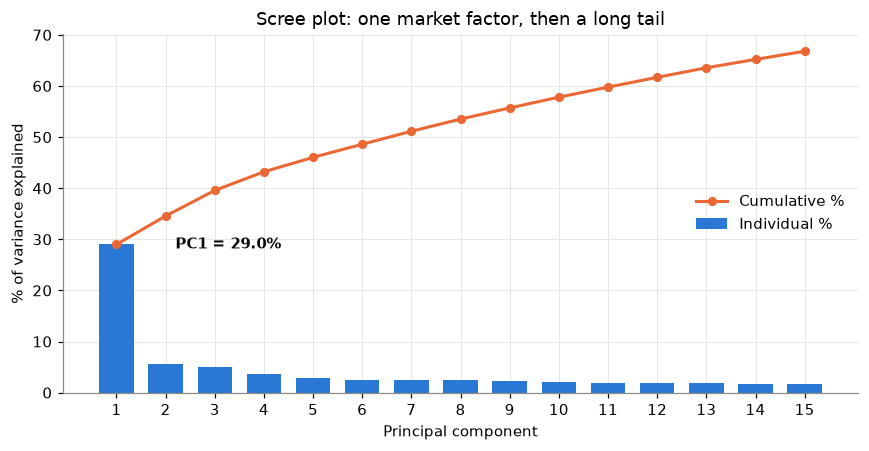

PC1 explains 29.0%; PC1–PC3 together 39.6%; 25 PCs needed for 80%
All PC1 loadings same sign → True | range 0.076 to 0.183


In [6]:
pca = PCA().fit(X)
evr = pca.explained_variance_ratio_
loadings = pd.DataFrame(pca.components_.T, index=returns.columns,
                        columns=[f"PC{i+1}" for i in range(len(evr))])
if loadings.PC1.mean() < 0: loadings.PC1 *= -1     # sign is arbitrary: orient PC1 so "market up" is positive

n90 = int(np.searchsorted(np.cumsum(evr), 0.80) + 1)
fig, ax = plt.subplots(figsize=(8, 4.2))
k = 15
ax.bar(range(1, k+1), evr[:k]*100, color="#2a78d6", width=0.7, zorder=2)
ax.plot(range(1, k+1), np.cumsum(evr[:k])*100, color="#eb6834", lw=2, marker="o", ms=5, zorder=3, label="Cumulative")
ax.annotate(f"PC1 = {evr[0]:.1%}", (1, evr[0]*100), xytext=(2.2, evr[0]*100), color=INK,
            va="center", fontweight="bold")
ax.set(xlabel="Principal component", ylabel="% of variance explained", xticks=range(1, k+1),
       title=f"Scree plot: one market factor, then a long tail")
ax.legend(["Cumulative %", "Individual %"], frameon=False, loc="center right")
plt.tight_layout(); plt.savefig("charts/1_scree.png"); plt.show()

same_sign = (loadings.PC1 > 0).all()
print(f"PC1 explains {evr[0]:.1%}; PC1–PC3 together {evr[:3].sum():.1%}; {n90} PCs needed for 80%")
print("All PC1 loadings same sign →", same_sign, "| range", loadings.PC1.min().round(3), "to", loadings.PC1.max().round(3))

## 6. Reading PC2 and PC3

In [7]:
def extremes(pc, n=6):
    s = loadings[pc].sort_values()
    return pd.DataFrame({"negative": [f"{t[:-3]} ({sector_of[t]})" for t in s.index[:n]],
                         "positive": [f"{t[:-3]} ({sector_of[t]})" for t in s.index[::-1][:n]]})
for pc in ["PC2", "PC3"]:
    print(f"\n{pc} ({evr[int(pc[2:])-1]:.1%} of variance)"); print(extremes(pc).to_string(index=False))

sector_load = loadings[["PC1", "PC2", "PC3"]].groupby(sector_of).mean().round(3).sort_values("PC2")
sector_load


PC2 (5.6% of variance)
                              negative                                positive
     ONGC (Oil Gas & Consumable Fuels)            TCS (Information Technology)
COALINDIA (Oil Gas & Consumable Fuels)           INFY (Information Technology)
                          NTPC (Power)        HCLTECH (Information Technology)
                     POWERGRID (Power)          TECHM (Information Technology)
                   BEL (Capital Goods) HINDUNILVR (Fast Moving Consumer Goods)
           TATASTEEL (Metals & Mining)          ASIANPAINT (Consumer Durables)

PC3 (5.0% of variance)
                                  negative                          positive
   MARUTI (Automobile and Auto Components)  HCLTECH (Information Technology)
   HINDUNILVR (Fast Moving Consumer Goods)     INFY (Information Technology)
            ASIANPAINT (Consumer Durables)    TECHM (Information Technology)
EICHERMOT (Automobile and Auto Components)      TCS (Information Technology)
    NESTLEIND 

,PC1,PC2,PC3
sector,,,
Power,0.137,-0.237,0.081
Capital Goods,0.152,-0.205,0.066
Oil Gas & Consumable Fuels,0.133,-0.196,0.167
Metals & Mining,0.161,-0.154,0.119
Services,0.161,-0.073,-0.063
Construction,0.179,-0.038,0.038
Financial Services,0.155,-0.004,-0.080
Consumer Services,0.127,0.007,-0.021
Construction Materials,0.178,0.013,-0.078


## 7. PC1 vs PC2 biplot
15 official sectors is too many colours to tell apart on a scatter, so colour uses 8 broad groups. Each dot also carries its ticker label and a marker shape, so you can read the chart without relying on colour.

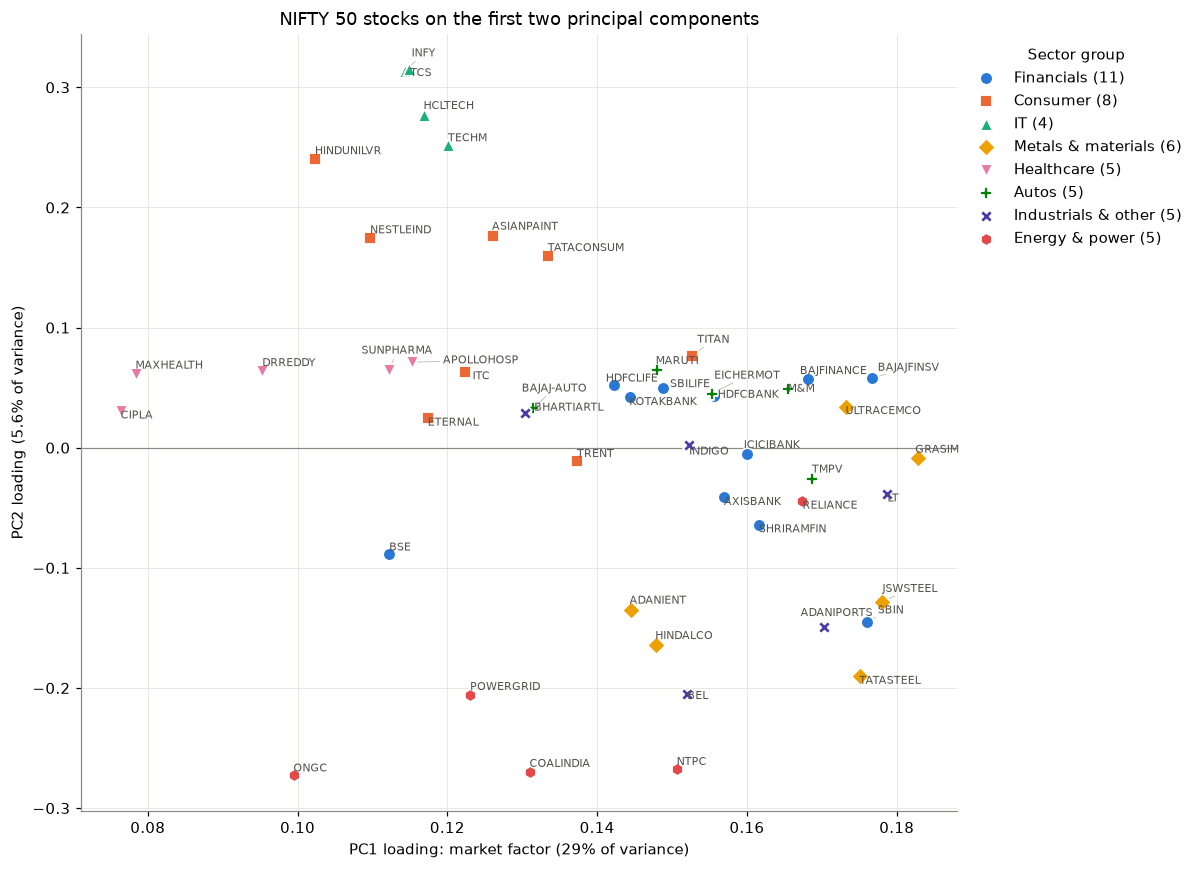

In [8]:
GROUP = {"Financial Services": "Financials", "Information Technology": "IT",
         "Healthcare": "Healthcare", "Fast Moving Consumer Goods": "Consumer",
         "Consumer Durables": "Consumer", "Consumer Services": "Consumer",
         "Automobile and Auto Components": "Autos", "Metals & Mining": "Metals & materials",
         "Construction Materials": "Metals & materials", "Oil Gas & Consumable Fuels": "Energy & power",
         "Power": "Energy & power", "Capital Goods": "Industrials & other", "Construction": "Industrials & other",
         "Services": "Industrials & other", "Telecommunication": "Industrials & other"}
PALETTE = dict(zip(["Financials", "Consumer", "IT", "Metals & materials", "Healthcare", "Autos",
                    "Industrials & other", "Energy & power"],
                   ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]))
MARKERS = dict(zip(PALETTE, ["o", "s", "^", "D", "v", "P", "X", "h"]))
group_of = sector_of.map(GROUP)

fig, ax = plt.subplots(figsize=(11, 8))
for g in PALETTE:
    idx = [t for t in loadings.index if group_of[t] == g]
    ax.scatter(loadings.loc[idx, "PC1"], loadings.loc[idx, "PC2"], s=70, c=PALETTE[g], marker=MARKERS[g],
               edgecolor="white", linewidth=1.2, label=f"{g} ({len(idx)})", zorder=3)
texts = [ax.text(loadings.at[t, "PC1"], loadings.at[t, "PC2"], t[:-3], fontsize=7.5, color=MUTED) for t in loadings.index]
adjust_text(texts, x=loadings.PC1.values, y=loadings.PC2.values, ax=ax,
            arrowprops=dict(arrowstyle="-", color="#b5b4ae", lw=0.5))
ax.axhline(0, color="#8a8984", lw=0.8);
ax.set(xlabel=f"PC1 loading: market factor ({evr[0]:.0%} of variance)",
       ylabel=f"PC2 loading ({evr[1]:.1%} of variance)",
       title="NIFTY 50 stocks on the first two principal components")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0), title="Sector group")
plt.tight_layout(); plt.savefig("charts/2_biplot_pc1_pc2.png", bbox_inches="tight"); plt.show()

## 8. Hierarchical clustering
Correlation distance `d = sqrt(2(1 − ρ))` is a true metric: it equals the Euclidean distance between two standardised return series, scaled by 1/√n. That is what makes Ward linkage valid here.
**Choosing K.** The silhouette score is low and almost flat across k = 5–7 (about 0.07–0.08). Beyond the market factor, the cluster structure is real but weak, which is normal for large caps in a single market.
So K is chosen on interpretability within that range: at k = 5, Ward leaves one 31-stock "everything domestic" blob. k = 7 is the first cut that splits it into banks, a new-age/insurance/hospitals group and domestic cyclicals.

Silhouette by k: {3: 0.064, 4: 0.071, 5: 0.079, 6: 0.071, 7: 0.074, 8: 0.085, 9: 0.089, 10: 0.099}
Chosen K = 7


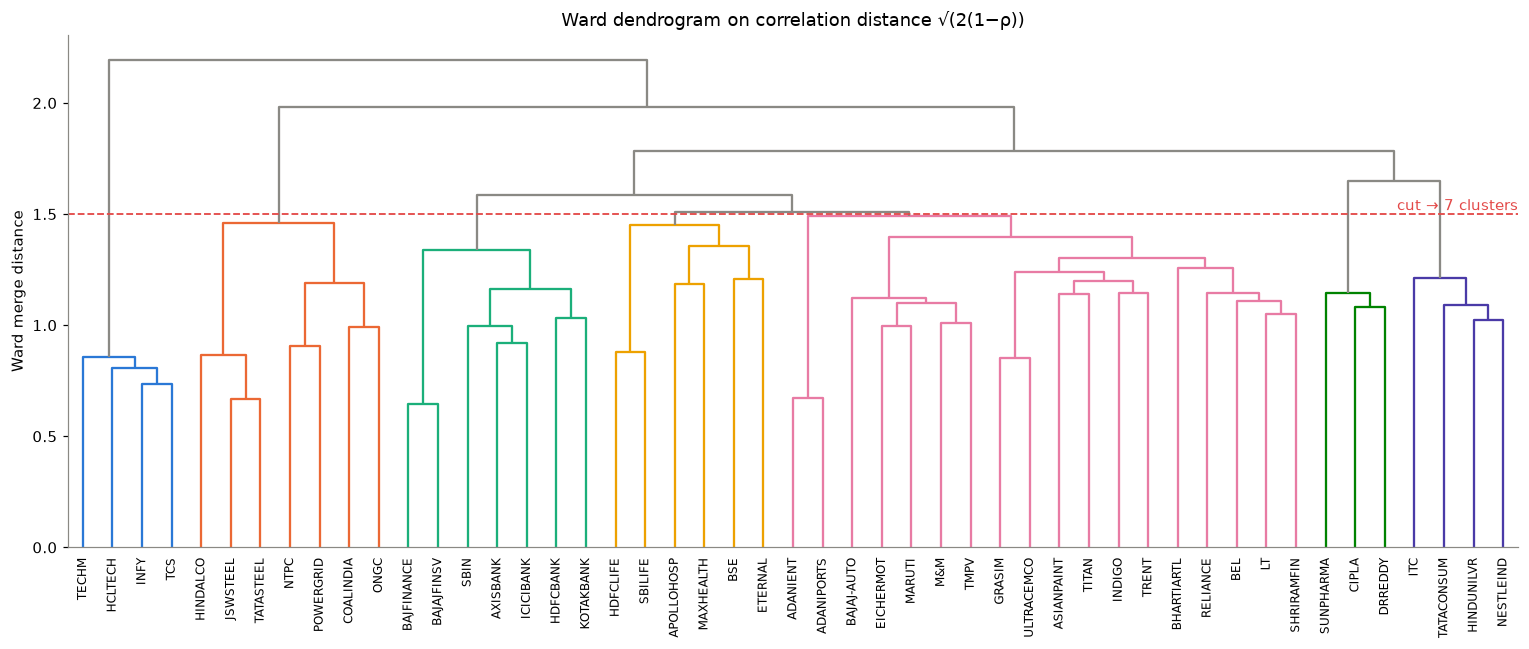

In [9]:
corr = returns.corr()
dist = np.sqrt(np.clip(2 * (1 - corr.values), 0, None)); np.fill_diagonal(dist, 0)
Z = linkage(squareform(dist, checks=False), method="ward")

sil = {k: silhouette_score(dist, fcluster(Z, k, "maxclust"), metric="precomputed") for k in range(3, 11)}
print("Silhouette by k:", {k: round(v, 3) for k, v in sil.items()})
K = 7
labels = pd.Series(fcluster(Z, K, "maxclust"), index=corr.index, name="cluster")
cut = (Z[-K, 2] + Z[-K+1, 2]) / 2
print("Chosen K =", K)

set_link_color_palette(["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"])
fig, ax = plt.subplots(figsize=(14, 6))
dendrogram(Z, labels=[t[:-3] for t in corr.index], color_threshold=cut, above_threshold_color="#8a8984",
           leaf_font_size=8, ax=ax)
ax.axhline(cut, color="#e34948", ls="--", lw=1.2); ax.text(ax.get_xlim()[1], cut, f"  cut → {K} clusters", color="#e34948", va="bottom", ha="right")
ax.set(title="Ward dendrogram on correlation distance √(2(1−ρ))", ylabel="Ward merge distance"); ax.grid(False)
plt.tight_layout(); plt.savefig("charts/4_dendrogram.png"); plt.show()

### Correlation heatmap ordered by cluster

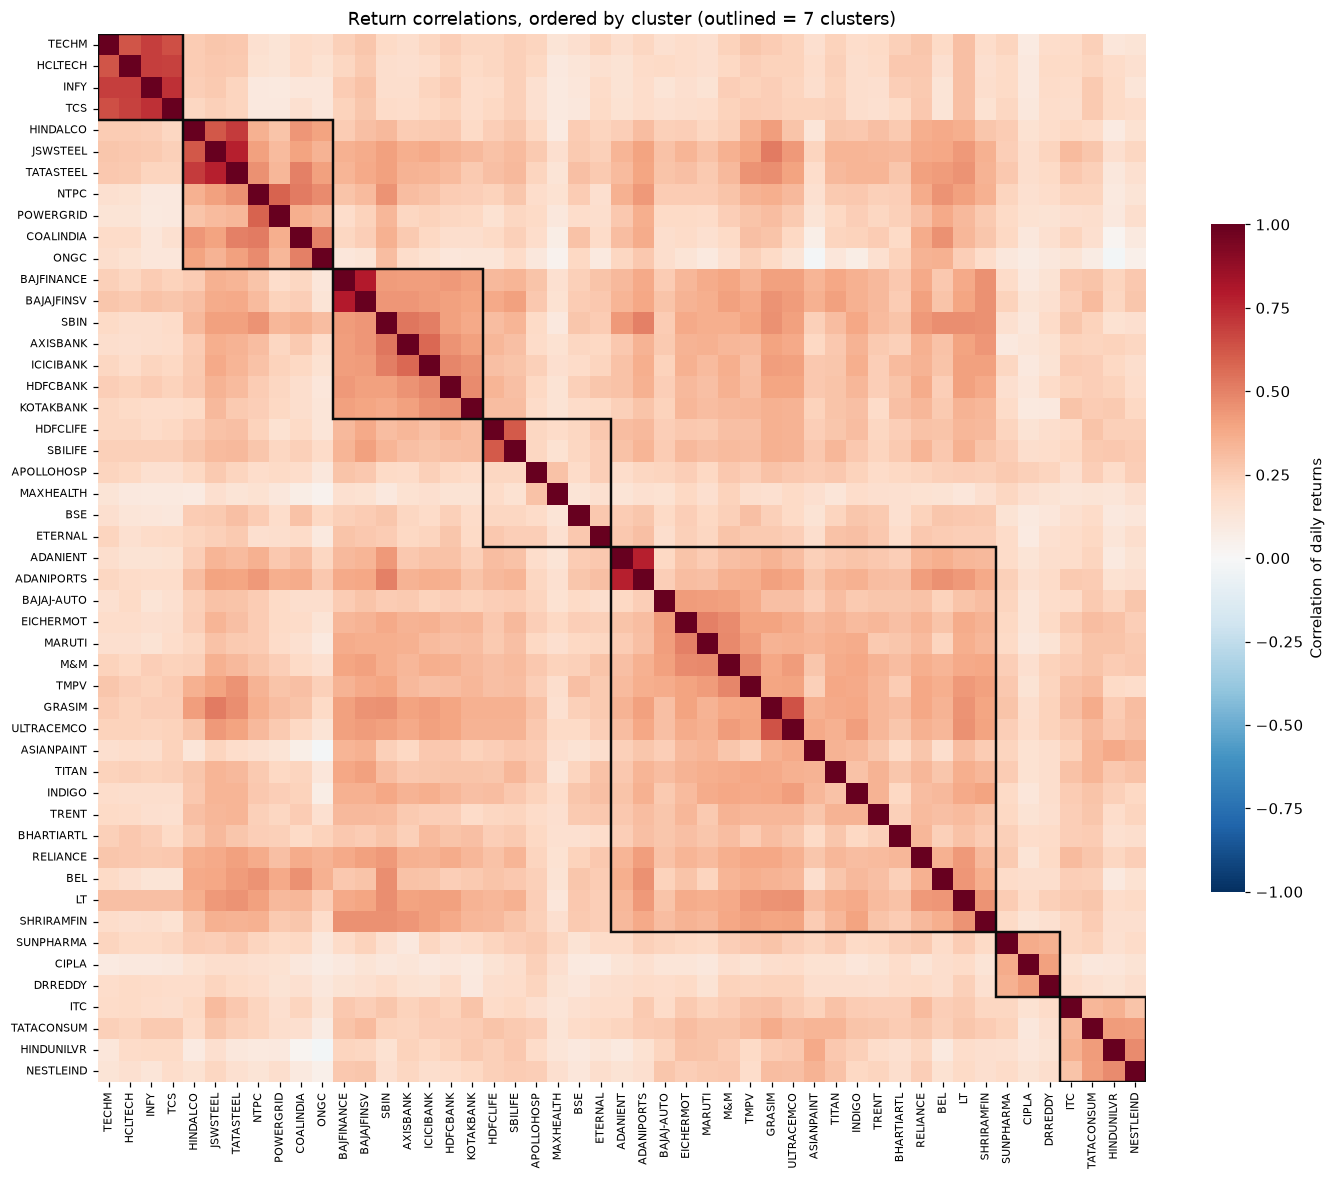

In [10]:
order = dendrogram(Z, no_plot=True)["leaves"]
ordered = corr.index[order]
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(corr.loc[ordered, ordered], cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True,
            xticklabels=[t[:-3] for t in ordered], yticklabels=[t[:-3] for t in ordered],
            cbar_kws={"shrink": 0.6, "label": "Correlation of daily returns"}, ax=ax)
# outline each cluster block
pos = 0
for c in pd.Series(labels[ordered].values).groupby((labels[ordered].values != np.roll(labels[ordered].values, 1)).cumsum()):
    n = len(c[1]); ax.add_patch(plt.Rectangle((pos, pos), n, n, fill=False, ec=INK, lw=1.6)); pos += n
ax.grid(False); ax.set(xlabel="", ylabel=""); ax.tick_params(labelsize=7.5); ax.set_title(f"Return correlations, ordered by cluster (outlined = {K} clusters)")
plt.tight_layout(); plt.savefig("charts/3_corr_heatmap_by_cluster.png"); plt.show()

## 9. Clusters vs official sectors

In [11]:
df = pd.DataFrame({"sector": sector_of[labels.index], "cluster": labels})
ct = pd.crosstab(df.sector, df.cluster, margins=True)
display(ct)

# Each cluster is labelled by its plurality sector. Each sector's "home cluster" is the cluster holding most of its stocks.
# A HIDDEN CO-MOVER is a stock outside its sector's home cluster. Sectors with one stock have no home and are left out.
# If a 2-stock sector splits 1–1, both stocks are flagged as a "split sector".
summary = []
for c, g in df.groupby("cluster"):
    vc = g.sector.value_counts()
    summary.append({"cluster": c, "size": len(g), "dominant_sector": vc.index[0], "purity": f"{vc.iloc[0]/len(g):.0%}",
                    "members": ", ".join(t[:-3] for t in g.index)})
summary = pd.DataFrame(summary)

hidden, split = [], []
for s, g in df.groupby("sector"):
    if len(g) < 2: continue
    vc = g.cluster.value_counts()
    if len(vc) > 1 and vc.iloc[0] == vc.iloc[1]:
        split += [{"stock": t[:-3], "sector": s, "cluster": c} for t, c in g.cluster.items()]; continue
    home = vc.index[0]
    for t, c in g.cluster.items():
        if c == home: continue
        mates = g.index.drop(t); clus = df.index[(df.cluster == c) & (df.index != t)]
        hidden.append({"stock": t[:-3], "official_sector": s, "home_cluster": home, "actual_cluster": c,
                       "actual_cluster_dominant": summary.set_index("cluster").at[c, "dominant_sector"],
                       "avg_corr_with_sector_mates": round(corr.loc[t, mates].mean(), 3),
                       "avg_corr_with_cluster_mates": round(corr.loc[t, clus].mean(), 3)})
hidden, split = pd.DataFrame(hidden), pd.DataFrame(split)
display(summary)
print(f"Hidden co-movers: {len(hidden)}  |  split sectors: {split.sector.unique().tolist() if len(split) else 'none'}")
display(split)
hidden

cluster,1,2,3,4,5,6,7,All
sector,,,,,,,,
Automobile and Auto Components,0,0,0,0,5,0,0,5
Capital Goods,0,0,0,0,1,0,0,1
Construction,0,0,0,0,1,0,0,1
Construction Materials,0,0,0,0,2,0,0,2
Consumer Durables,0,0,0,0,2,0,0,2
Consumer Services,0,0,0,1,1,0,0,2
Fast Moving Consumer Goods,0,0,0,0,0,0,4,4
Financial Services,0,0,7,3,1,0,0,11
Healthcare,0,0,0,2,0,3,0,5


,cluster,size,dominant_sector,purity,members
0,1,4,Information Technology,100%,"HCLTECH, INFY, TCS, TECHM"
1,2,7,Metals & Mining,43%,"COALINDIA, HINDALCO, JSWSTEEL, NTPC, ONGC, POW..."
2,3,7,Financial Services,100%,"AXISBANK, BAJFINANCE, BAJAJFINSV, HDFCBANK, IC..."
3,4,6,Financial Services,50%,"APOLLOHOSP, BSE, ETERNAL, HDFCLIFE, MAXHEALTH,..."
4,5,18,Automobile and Auto Components,28%,"ADANIENT, ADANIPORTS, ASIANPAINT, BAJAJ-AUTO, ..."
5,6,3,Healthcare,100%,"CIPLA, DRREDDY, SUNPHARMA"
6,7,4,Fast Moving Consumer Goods,100%,"HINDUNILVR, ITC, NESTLEIND, TATACONSUM"


Hidden co-movers: 8  |  split sectors: ['Consumer Services']


,stock,sector,cluster
0,ETERNAL,Consumer Services,4
1,TRENT,Consumer Services,5


,stock,official_sector,home_cluster,actual_cluster,actual_cluster_dominant,avg_corr_with_sector_mates,avg_corr_with_cluster_mates
0,BSE,Financial Services,3,4,Financial Services,0.231,0.205
1,HDFCLIFE,Financial Services,3,4,Financial Services,0.345,0.301
2,SBILIFE,Financial Services,3,4,Financial Services,0.340,0.289
3,SHRIRAMFIN,Financial Services,3,5,Automobile and Auto Components,0.381,0.350
4,APOLLOHOSP,Healthcare,6,4,Financial Services,0.254,0.231
5,MAXHEALTH,Healthcare,6,4,Financial Services,0.206,0.188
6,ADANIENT,Metals & Mining,2,5,Automobile and Auto Components,0.301,0.321
7,RELIANCE,Oil Gas & Consumable Fuels,2,5,Automobile and Auto Components,0.360,0.345


### Robustness check: market-neutral clustering
PC1, the market, drives about 29% of every stock's variance and pulls everything towards one blob. This check removes PC1 and re-clusters on the residual correlations.
The Adjusted Rand Index (ARI) measures how far the two partitions agree. Both partitions are also compared to the official sectors.

In [12]:
from sklearn.metrics import adjusted_rand_score
p1 = PCA(1).fit(X); Xr = X - p1.transform(X) @ p1.components_
rcorr = np.corrcoef(Xr.T)
rd = np.sqrt(np.clip(2 * (1 - rcorr), 0, None)); np.fill_diagonal(rd, 0)
rlabels = pd.Series(fcluster(linkage(squareform(rd, checks=False), "ward"), K, "maxclust"), index=corr.index)
ari_raw_vs_resid = adjusted_rand_score(labels, rlabels)
ari_raw_vs_sector = adjusted_rand_score(df.sector, labels)
ari_resid_vs_sector = adjusted_rand_score(df.sector, rlabels)
print(f"ARI raw vs market-neutral clusters: {ari_raw_vs_resid:.2f}")
print(f"ARI raw clusters vs official sectors: {ari_raw_vs_sector:.2f} | market-neutral vs sectors: {ari_resid_vs_sector:.2f}")
for c, g in rlabels.groupby(rlabels): print(c, [t[:-3] for t in g.index])

ARI raw vs market-neutral clusters: 0.61
ARI raw clusters vs official sectors: 0.27 | market-neutral vs sectors: 0.33
1 ['HINDALCO', 'JSWSTEEL', 'TATASTEEL']
2 ['ADANIENT', 'ADANIPORTS', 'BEL', 'COALINDIA', 'NTPC', 'ONGC', 'POWERGRID']
3 ['HCLTECH', 'INFY', 'TCS', 'TECHM']
4 ['AXISBANK', 'BAJFINANCE', 'BAJAJFINSV', 'HDFCBANK', 'ICICIBANK', 'KOTAKBANK', 'SBIN']
5 ['BSE', 'BAJAJ-AUTO', 'BHARTIARTL', 'EICHERMOT', 'ETERNAL', 'GRASIM', 'INDIGO', 'LT', 'M&M', 'MARUTI', 'RELIANCE', 'SHRIRAMFIN', 'TMPV', 'TITAN', 'TRENT', 'ULTRACEMCO']
6 ['ASIANPAINT', 'HINDUNILVR', 'ITC', 'NESTLEIND', 'TATACONSUM']
7 ['APOLLOHOSP', 'CIPLA', 'DRREDDY', 'HDFCLIFE', 'MAXHEALTH', 'SBILIFE', 'SUNPHARMA']


## 10. Findings

In [13]:
results = {
    "n_stocks_analysed": int(returns.shape[1]), "n_days": int(returns.shape[0]),
    "dropped": {t: round(float(v), 3) for t, v in dropped.items()},
    "pc1_var": round(float(evr[0]), 4), "pc2_var": round(float(evr[1]), 4), "pc3_var": round(float(evr[2]), 4),
    "pcs_for_80pct": n90, "pc1_all_same_sign": bool(same_sign),
    "pc1_top": loadings.PC1.nlargest(5).round(3).rename(lambda t: t[:-3]).to_dict(),
    "pc1_bottom": loadings.PC1.nsmallest(5).round(3).rename(lambda t: t[:-3]).to_dict(),
    "pc2_pos": loadings.PC2.nlargest(6).round(3).rename(lambda t: t[:-3]).to_dict(),
    "pc2_neg": loadings.PC2.nsmallest(6).round(3).rename(lambda t: t[:-3]).to_dict(),
    "pc3_pos": loadings.PC3.nlargest(6).round(3).rename(lambda t: t[:-3]).to_dict(),
    "pc3_neg": loadings.PC3.nsmallest(6).round(3).rename(lambda t: t[:-3]).to_dict(),
    "silhouette": {int(k): round(float(v), 4) for k, v in sil.items()}, "K": int(K),
    "clusters": summary.to_dict("records"), "hidden": hidden.to_dict("records"),
    "n_hidden": len(hidden), "split": split.to_dict("records"),
    "ari_raw_vs_resid": round(ari_raw_vs_resid, 3), "ari_raw_vs_sector": round(ari_raw_vs_sector, 3),
    "ari_resid_vs_sector": round(ari_resid_vs_sector, 3),
    "resid_clusters": {int(c): [t[:-3] for t in g.index] for c, g in rlabels.groupby(rlabels)},
    "mean_pairwise_corr": round(float(corr.values[np.triu_indices_from(corr, 1)].mean()), 3),
}
json.dump(results, open("results.json", "w"), indent=2, default=str)
loadings[["PC1", "PC2", "PC3"]].assign(sector=sector_of, cluster=labels).round(4).to_csv("data/loadings_and_clusters.csv")
print(f"PC1 explains {evr[0]:.0%} of variance; {len(hidden)} stocks move with a different group than their sector, "
      f"including {', '.join(hidden.stock.head(3))}.")

PC1 explains 29% of variance; 8 stocks move with a different group than their sector, including BSE, HDFCLIFE, SBILIFE.
